# Week 3: clipping, gradient boosting, and rolling averages

Same steps as `src/04_week3.py`, with explanations. Shared helpers live in `src/cmapss.py`.

**Three upgrades this week:** (1) clip the labels at 125, (2) a stronger model, (3) smoothed sensor features. Two of them worked and one did not.

In [1]:
import sys, warnings
sys.path.insert(0, '../src')   # let the notebook find our helper file in src/
# numpy 2.0 on Apple chips prints false 'overflow in matmul' alarms (verified harmless in Week 2)
warnings.filterwarnings('ignore', message='.*encountered in matmul')
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from cmapss import (RUL_CAP, ENGINE_COLORS, load_train, clip_rul, feature_columns, split_by_engine,
                    load_test_last_rows, rmse, add_rolling_features, cross_validate_by_engine,
                    plot_predicted_vs_true, plot_scoreboard)

train = load_train()               # labels as they really are (raw)
train_c = clip_rul(train)          # labels capped at 125
features = feature_columns(train)  # the 17 clue columns
test_last = load_test_last_rows()  # last flight of each test engine + true RUL
results = {}                       # model name -> (test RMSE, predictions)

## Step 1: Clip RUL at 125

A healthy engine's sensors look the same at 300 flights left as at 150, so asking the model to tell those apart is asking the impossible. **Clipping** relabels everything above 125 as exactly 125, meaning "healthy". Only the *training labels* are clipped; test engines are still graded against NASA's true answers.

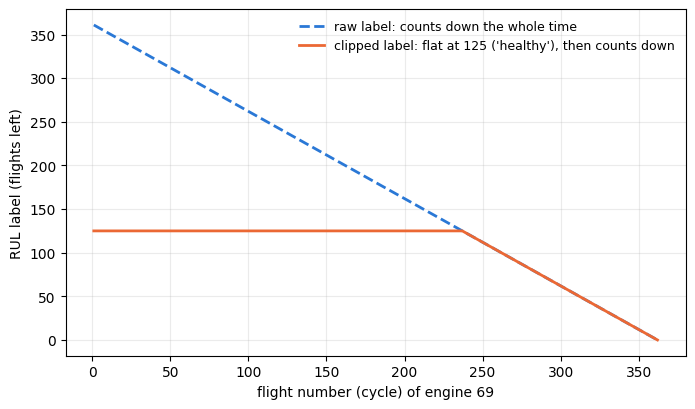

In [2]:
longest = int(train.groupby('unit').cycle.max().idxmax())
raw, clip = train[train.unit == longest], train_c[train_c.unit == longest]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(raw.cycle, raw.RUL, '--', color=ENGINE_COLORS[0], lw=2, label='raw label: counts down the whole time')
ax.plot(clip.cycle, clip.RUL, color=ENGINE_COLORS[1], lw=2, label=f"clipped label: flat at {RUL_CAP} ('healthy'), then counts down")
ax.set_xlabel(f'flight number (cycle) of engine {longest}'); ax.set_ylabel('RUL label (flights left)')
ax.grid(alpha=0.25); ax.legend(frameon=False, fontsize=9);

In [3]:
# Same model as Week 2; the ONLY change is the labels it learns from.
for name, data in [('Linear regression, raw labels', train),
                   (f'Linear regression, clipped at {RUL_CAP}', train_c)]:
    pred = LinearRegression().fit(data[features], data.RUL).predict(test_last[features])
    results[name] = (rmse(test_last.RUL, pred), pred)
    print(f'{name:40s} TEST RMSE {results[name][0]:.2f}   too high for {(pred > test_last.RUL).sum()} of 100 engines')

Linear regression, raw labels            TEST RMSE 32.04   too high for 85 of 100 engines
Linear regression, clipped at 125        TEST RMSE 21.90   too high for 58 of 100 engines


Clipping alone takes the same model from about 32 to about 22, and the unsafe habit of guessing too high mostly disappears.

## Step 2: Gradient boosting

A straight line can't follow curved wear. **Gradient boosting** builds 100 small decision trees, each one correcting the mistakes left by the trees before it, like a team of tutors where each new tutor only works on what the team still gets wrong. The trees are kept tiny (3 questions deep) so none of them can memorize.

First the overfitting check: engines it studied vs engines it never saw.

In [4]:
def new_gb():
    return GradientBoostingRegressor(n_estimators=100, max_depth=3, random_state=0)

tr, val = split_by_engine(train_c)
rows = []
for name, m in [('linear regression', LinearRegression()), ('gradient boosting', new_gb())]:
    m.fit(tr[features], tr.RUL)
    rows.append({'model': name, 'studied engines': rmse(tr.RUL, m.predict(tr[features])),
                 'unseen engines': rmse(val.RUL, m.predict(val[features]))})
pd.DataFrame(rows).round(2)

,model,studied engines,unseen engines
0,linear regression,21.40,21.82
1,gradient boosting,17.57,18.52


In [5]:
pred = new_gb().fit(train_c[features], train_c.RUL).predict(test_last[features])
name = f'Gradient boosting, clipped at {RUL_CAP}'
results[name] = (rmse(test_last.RUL, pred), pred)
print(f'{name}: TEST RMSE {results[name][0]:.2f}   too high for {(pred > test_last.RUL).sum()} of 100 engines')

Gradient boosting, clipped at 125: TEST RMSE 18.36   too high for 53 of 100 engines


The gap between studied and unseen engines is about one flight: a real pattern, not memorization. Test RMSE is about 18.4.

## Step 3: Rolling-window features (this one did not help)

Single sensor readings are jumpy. A **rolling average** adds, for each sensor, the average of its last several flights, which cancels random wiggles. It only looks backwards (never at future flights) and is computed per engine.

How many flights to average? We let **cross-validation** decide: the 100 engines are split into 5 groups, each group takes a turn as the practice exam, and we average the 5 scores. The test set is not used for this choice. *(This cell trains 25 models and takes a few minutes.)*

In [6]:
rows = []
for window in [None, 5, 10, 20, 30]:
    data = train_c if window is None else add_rolling_features(train_c, window)
    cols = features + [c for c in data.columns if '_avg' in c]
    mean, folds = cross_validate_by_engine(new_gb, data, cols)
    rows.append({'window': 'none' if window is None else window, 'average RMSE': mean,
                 'lowest exam': min(folds), 'highest exam': max(folds)})
cv = pd.DataFrame(rows).round(2)
cv

,window,average RMSE,lowest exam,highest exam
0,none,18.57,16.55,20.51
1,5,18.22,15.92,20.35
2,10,18.42,16.13,20.73
3,20,18.49,16.42,20.70
4,30,18.27,16.36,20.05


**Reading the table:** the windows differ by a few tenths of a flight, while the five practice exams differ from each other by about four flights. The differences between windows are noise. Below, the nominal winner (window 5) is scored on the test set.

In [7]:
best = 5
add_best = lambda df: add_rolling_features(df, best)
train_r = add_best(train_c)
roll_cols = features + [c for c in train_r.columns if '_avg' in c]
test_last_r = load_test_last_rows(add_features=add_best)
for label, make in [('Linear regression', LinearRegression), ('Gradient boosting', new_gb)]:
    pred = make().fit(train_r[roll_cols], train_r.RUL).predict(test_last_r[roll_cols])
    name = f'{label}, clipped + rolling avg ({best})'
    results[name] = (rmse(test_last_r.RUL, pred), pred)
    print(f'{name:44s} TEST RMSE {results[name][0]:.2f}')

Linear regression, clipped + rolling avg (5) TEST RMSE 21.79


Gradient boosting, clipped + rolling avg (5) TEST RMSE 18.43


**Honest result:** rolling averages left gradient boosting where it was (about 18.4 either way). A separate check confirmed the averages are computed correctly, so this is a real finding. A likely reason, not proven: random noise is not the main limit. The model already looks at 15 sensors at once, which cancels much of the noise, and what remains is that different engines can show the same readings with different amounts of life left.

## Step 4: The scoreboard

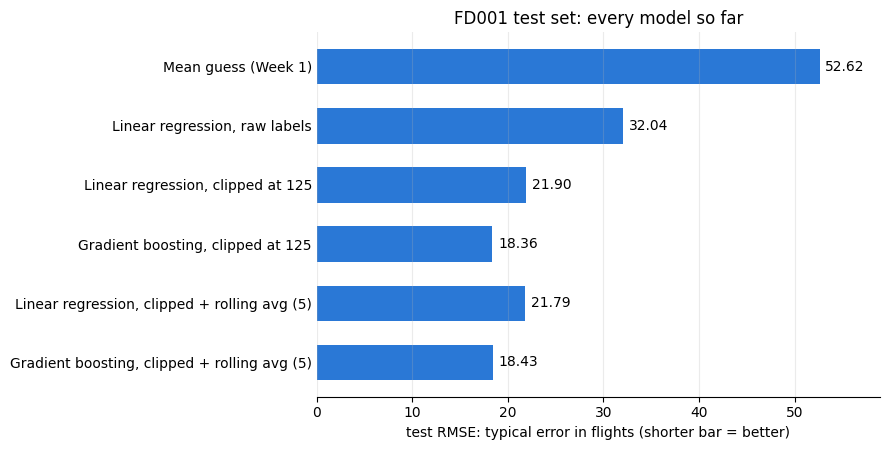

In [8]:
scores = {'Mean guess (Week 1)': rmse(test_last.RUL, [train.RUL.mean()] * len(test_last))}
scores.update({n: s for n, (s, _) in results.items()})
fig = plot_scoreboard(scores, 'FD001 test set: every model so far')

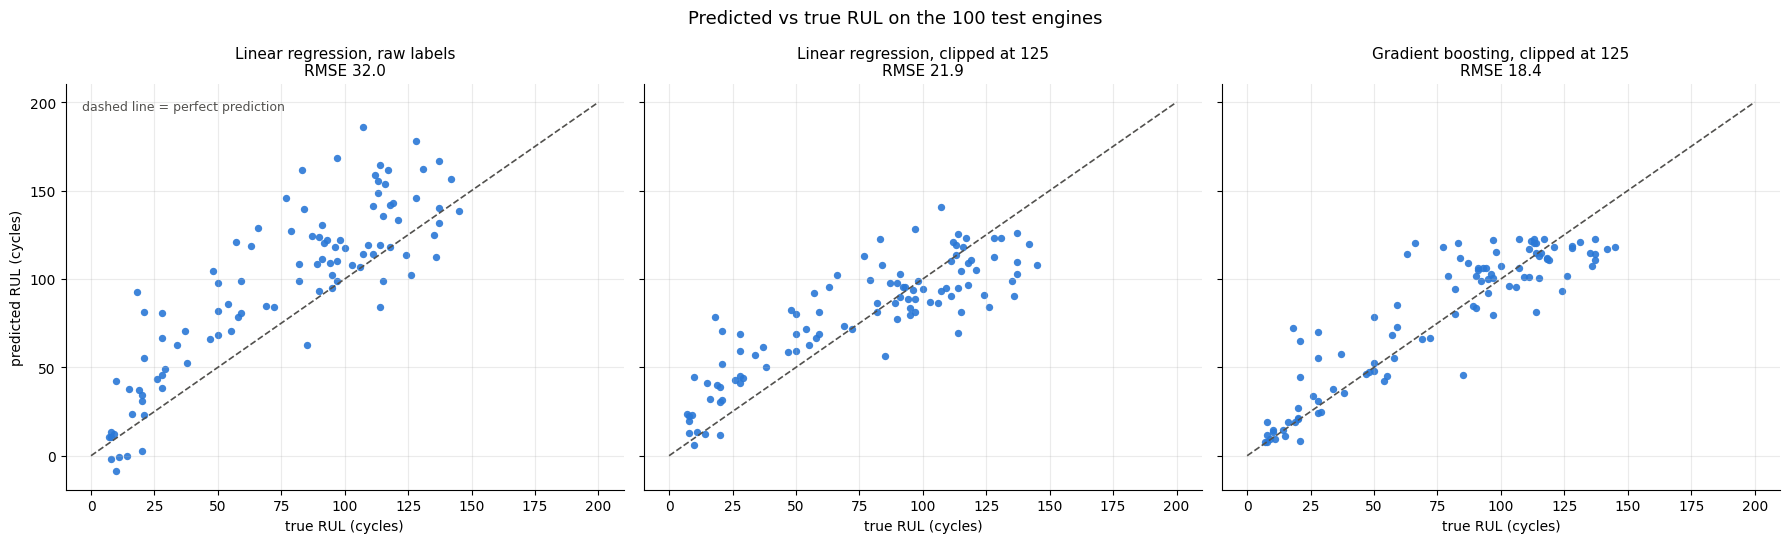

In [9]:
show = ['Linear regression, raw labels', f'Linear regression, clipped at {RUL_CAP}',
        f'Gradient boosting, clipped at {RUL_CAP}']
fig = plot_predicted_vs_true([(n, test_last.RUL, results[n][1]) for n in show],
                             'Predicted vs true RUL on the 100 test engines', limit=200)

**Reading the three panels left to right:** the dots tighten around the dashed "perfect" line. Raw labels: most dots sit above the line (guessing too high). Clipped: centered on the line. Gradient boosting: tightest of all, especially near failure (bottom-left), where accuracy matters most. Its predictions level off near 125 because that is the largest label it ever saw.

**Best model so far: gradient boosting with clipped labels, test RMSE about 18.4.**